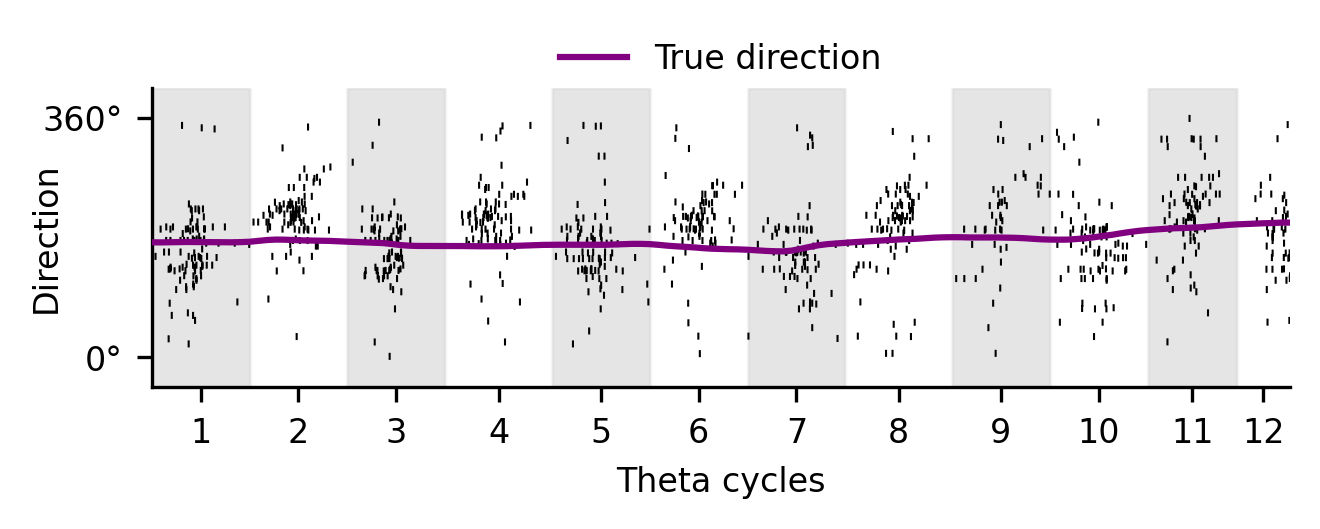

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# --------------------------------------------------
# load matlab file
# --------------------------------------------------
mat_path = "./empirical_data/raster_directionalSweep.mat"
data = loadmat(mat_path, simplify_cells=True)
plotData = data["plotData"]

# --------------------------------------------------
# helpers
# --------------------------------------------------
def arr(x):
    return np.asarray(x).squeeze()

def cell_to_list(x):
    if isinstance(x, list):
        return [np.asarray(xx).squeeze() for xx in x]
    x = np.asarray(x, dtype=object).squeeze()
    if x.ndim == 0:
        return [np.asarray(x.item()).squeeze()]
    return [np.asarray(xx).squeeze() for xx in x]

def wrap_0_2pi(y):
    return np.mod(np.asarray(y, dtype=float), 2 * np.pi)

def clip_to_range(y, yrange):
    y = np.asarray(y, dtype=float).copy()
    keep = (y >= yrange[0]) & (y <= yrange[1])
    y[~keep] = np.nan
    return y

# --------------------------------------------------
# extract saved fields
# --------------------------------------------------
t_hd = arr(plotData["t_hd"]).astype(float)
y_hd_saved = arr(plotData["y_hd"]).astype(float)

raster_prefdir = arr(plotData["raster_prefdir"]).astype(float)
raster_yHeight = float(arr(plotData["raster_yHeight"]))
raster_color = arr(plotData["raster_color"]).astype(float)
raster_tickWidth = float(arr(plotData["raster_tickWidth"]))
raster_spikeTimes = cell_to_list(plotData["raster_spikeTimes"])

x_id = arr(plotData["x_id"]).astype(float)
y_id = arr(plotData["y_id"]).astype(float)
id_color = arr(plotData["id_color"]).astype(float)
id_lineWidth = float(arr(plotData["id_lineWidth"]))

fontSz = 8
xlim_ = arr(plotData["xlim"]).astype(float)

# 只显示后面一半时间窗口
xmid = xlim_[0] + 0.5 * (xlim_[1] - xlim_[0])
xlim_ = np.array([xmid, xlim_[1]], dtype=float)

# theta shading 也跟着只用这个后半段
theta_timeRange = xlim_.copy()

xline_x = float(arr(plotData["xline"]))

scale_bar_x = arr(plotData["scale_bar_x"]).astype(float)
scale_bar_y = arr(plotData["scale_bar_y"]).astype(float)
scale_bar_text_x = float(arr(plotData["scale_bar_text_x"]))
scale_bar_text_y = float(arr(plotData["scale_bar_text_y"]))
scale_bar_text = str(plotData["scale_bar_text"])

theta_cycleTimes = np.asarray(plotData["theta_cycleTimes"], dtype=float)
theta_timeRange = arr(plotData["theta_timeRange"]).astype(float)


# --------------------------------------------------
y_hd=y_hd_saved
#y_hd = wrap_0_2pi(y_hd_saved + np.pi)

# green and raster are already in the +pi frame
y_id = wrap_0_2pi(y_id)
raster_prefdir = wrap_0_2pi(raster_prefdir)

# --------------------------------------------------
# y-axis in radians, displayed as 0 and 360
# --------------------------------------------------
margin = np.deg2rad(45)
ylim_manual = np.array([-margin, 2 * np.pi + margin], dtype=float)
ytick_manual = [0, 2 * np.pi]
yticklabels_manual = ["0°", "360°"]

# --------------------------------------------------
# rebuild raster exactly like MATLAB raster2
# --------------------------------------------------
xAll = []
yAll = []

for u in range(len(raster_spikeTimes)):
    tt = np.asarray(raster_spikeTimes[u], dtype=float).ravel()
    if tt.size == 0:
        continue
    yy = np.full(tt.shape, raster_prefdir[u], dtype=float)
    xAll.append(tt)
    yAll.append(yy)

if len(xAll) > 0:
    xAll = np.concatenate(xAll)
    yAll = np.concatenate(yAll)

    xPlot = np.tile(xAll, (3, 1))
    xPlot[2, :] = np.nan
    xPlot = xPlot.reshape(-1, order="F")

    yPlot = np.tile(yAll, (3, 1)) + np.array([[0.5], [-0.5], [0.0]]) * raster_yHeight
    yPlot[2, :] = np.nan
    yPlot = yPlot.reshape(-1, order="F")

    yPlot = clip_to_range(yPlot, ylim_manual)
else:
    xPlot = np.array([])
    yPlot = np.array([])

# clip traces
y_hd_plot = clip_to_range(y_hd, ylim_manual)
y_id_plot = clip_to_range(y_id, ylim_manual)

# --------------------------------------------------
# theta shading
# --------------------------------------------------
def plot_shaded_theta_cycles(ax, cycleTimes, timeRange):
    ct = np.asarray(cycleTimes, dtype=float)

    if ct.ndim == 1:
        t1 = ct.copy()
        t2 = np.r_[t1[1:], np.inf]
    elif ct.ndim == 2 and ct.shape[1] == 1:
        t1 = ct[:, 0].copy()
        t2 = np.r_[t1[1:], np.inf]
    else:
        t1 = ct[:, 0].copy()
        t2 = ct[:, 1].copy()

    tmin, tmax = timeRange
    v2 = (t2 >= tmin) & (t2 <= tmax)
    v1 = (t1 >= tmin) & (t1 <= tmax)

    truncstart = np.where((~v1) & v2)[0]
    truncend = np.where(v1 & (~v2))[0]

    if truncstart.size > 0:
        t1[truncstart[0]] = tmin
    if truncend.size > 0 and truncend[0] + 1 < len(t1):
        t1[truncend[0] + 1] = tmax

    validCycles = (t1 >= tmin) & (t1 <= tmax)
    tnewcyc = t1[validCycles]

    # 只保留后面一小段 theta cycles，避免太密
    # 只保留最后 10 个 theta cycles
    # 只保留最后 10 个 theta cycles
    n_cycles_to_show = 12
    tnewcyc = tnewcyc[-(n_cycles_to_show + 1):]

    if len(tnewcyc) < 2:
        return np.array([]), None

    cycle_centers = []

    yl = ax.get_ylim()
    for i in range(len(tnewcyc) - 1):
        alpha = 0.1 if (i % 2 == 0) else 0.0

        x0 = tnewcyc[i]
        x1 = tnewcyc[i + 1]
        xmid = 0.5 * (x0 + x1)
        cycle_centers.append(xmid)

        ax.fill(
            [x0, x0, x1, x1, x0],
            [yl[0], yl[1], yl[1], yl[0], yl[0]],
            color="k",
            alpha=alpha,
            edgecolor=(0.6, 0.6, 0.6),
            linewidth=0.8,
            zorder=0
        )

    return np.asarray(cycle_centers), np.array([tnewcyc[0], tnewcyc[-1]])



# --------------------------------------------------
# plot
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(4.5, 2), dpi=300)

ax.set_ylim(ylim_manual)

cycle_centers, theta_xlim = plot_shaded_theta_cycles(
    ax,
    theta_cycleTimes,
    theta_timeRange
)

if theta_xlim is not None:
    ax.set_xlim(theta_xlim)
else:
    ax.set_xlim(xlim_)

ax.plot(t_hd, y_hd_plot, color="purple", zorder=3, linewidth=1.5, label="True direction")

if xPlot.size > 0:
    ax.plot(xPlot, yPlot, color=raster_color, linewidth=raster_tickWidth, zorder=2)

#ax.plot(x_id, y_id_plot, "-o", color=id_color, linewidth=id_lineWidth, markersize=4, zorder=4)

ax.axvline(xline_x, color="k", linewidth=1)

ax.plot(scale_bar_x, scale_bar_y, color="k", linewidth=1, clip_on=False)


ax.set_yticks(ytick_manual)
ax.set_yticklabels(yticklabels_manual)
ax.set_xticks(cycle_centers)
ax.set_xticklabels(np.arange(1, len(cycle_centers) + 1))

ax.tick_params(labelsize=fontSz)
ax.set_ylabel("Direction", fontsize=fontSz, labelpad=-5)
ax.set_xlabel("Theta cycles", fontsize=fontSz)

ax.legend(loc="upper center", fontsize=fontSz, frameon=False, bbox_to_anchor=(0.5, 1.25))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig("./docs/Raster_DirectionalSweep.pdf")

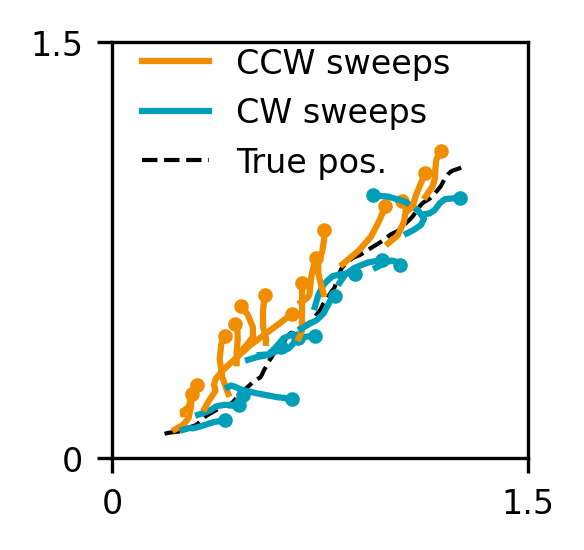

In [2]:
#Grid Cell Sweep Along Trajectory
#Session: 25843_1

# =========================================================
# Load saved data ONLY
# =========================================================
data = np.load("./empirical_data/GridSweep_alongTrajectory.npz", allow_pickle=True)

t          = data["t"]
pos        = data["pos"]
possm      = data["possm"]
decpos     = data["decpos"]
sweeps_sel = data["sweeps_sel"]
inds       = data["inds"]
vt         = data["vt"]

# =========================================================
# Plot
# =========================================================
plt.figure(figsize=(1.8, 1.8), dpi=300)

# Arena
# plt.plot(np.array([0, 1.5, 1.5, 0, 0]) - 0.75,
#          np.array([0, 0, 1.5, 1.5, 0]) - 0.75, "k")

# Tracking trajectory with da
ptracking, = plt.plot(pos[vt, 0], pos[vt, 1], color='k', linewidth=1, linestyle='--')

# Sweeps
hswp = []
for s, sw in enumerate(sweeps_sel[:-1]):
    start = sw["iStart"] - 1
    stop = sw["iStop"]
    swp = decpos[start:stop, :]

    col = '#009FB9' if (s % 2 == 1) else '#F18D00'

    h, = plt.plot(swp[:, 0], swp[:, 1], color=col)
    hswp.append(h)
    plt.plot(swp[-1, 0], swp[-1, 1], ".", markersize=5, color=col)

# # Start position
# hstart = plt.scatter(pos[inds[0], 0], pos[inds[0], 1], s=100, color="r", marker="*")


# Legend
legend_handles = []
legend_labels = []

if len(hswp) > 0:
    legend_handles.append(hswp[0]); legend_labels.append("CCW sweeps")
if len(hswp) > 1:
    legend_handles.append(hswp[1]); legend_labels.append("CW sweeps")

legend_handles += [ptracking]
legend_labels += ["True pos."]

plt.legend(legend_handles, legend_labels,
           loc="center left", bbox_to_anchor=(0.0, 0.83), 
           fontsize=8, frameon=False)

# Axes
plt.gca().invert_yaxis()
plt.gca().set_aspect("equal", "box")
plt.xticks([-0.75, 0.75], [0, 1.5])
plt.yticks([-0.75, 0.75], [1.5, 0])
#set tick size as 8
plt.gca().tick_params(axis='both', which='major', labelsize=8)

# Save figure as PDF
plt.savefig("./docs/GridSweep_alongTrajectory.pdf", format="pdf", bbox_inches="tight")



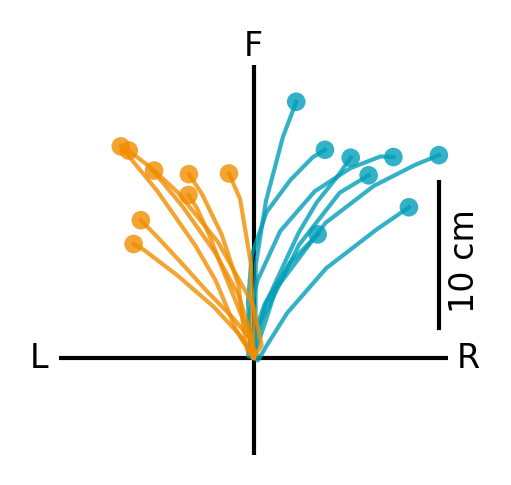

In [3]:
#Allocentric Palm Tree Sweeps
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt

# ---------------- LOAD MATLAB DATA ----------------
savePath = './empirical_data'
matFile = sio.loadmat(f'{savePath}/twoExamplePlots_individualSweeps_v2.mat', squeeze_me=True)
allPlots = matFile['allPlots']


# ---------------- NEW COLORS ----------------
baseCols = {
    'right': '#009FB9',  # orange
    'left':  '#F18D00'   # teal
}

# ---------------- PLOTTING ----------------
for p_idx, plotData in enumerate(np.atleast_1d(allPlots)):
    if p_idx==1:
        continue
    session = plotData['session']  # string
    sweeps = plotData['sweeps']
    fds = ['right','left']

    fig, ax = plt.subplots(figsize=(1.8,1.8), dpi=300)
    
    
    # axis labels L / R / F
    ax.text(-0.22, 0, "L", ha="center", va="center", fontsize=8)
    ax.text(0.22, 0, "R", ha="center", va="center", fontsize=8)
    ax.text(0, 0.32, "F", ha="center", va="center", fontsize=8)

    ax.axhline(0, color='k', linewidth=1)
    ax.axvline(0, color='k', linewidth=1)
    ax.set_xlim(-0.2, 0.2)
    ax.set_ylim(-0.1, 0.3)
    ax.set_aspect('equal')
    ax.axis('off')

    # scale bar
    barX = 0.19
    ax.plot([barX, barX],[0.03,0.18],'k', linewidth=1)
    ax.text(barX+0.01,0.10,"10 cm", fontsize=8, rotation=90, va='center')

    # ax.set_title(f"{session} ", fontsize=10, pad=20)

    for fd in fds:
        sweeps_fd = sweeps[fd]
        color_rgba = baseCols[fd]
     

        for pts in np.atleast_1d(sweeps_fd):
            pts = np.array(pts)
            for pt in pts:
                pt=pt-pt[0,:]
                
                ax.plot(pt[:,0], pt[:,1], '-', color=color_rgba, linewidth=1, alpha=0.8)
                ax.scatter(pt[-1,0], pt[-1,1], c=[color_rgba], s=20, alpha=0.8, edgecolors='none')
    

plt.tight_layout()
plt.savefig("./docs/GridSweep_averaged.pdf", format="pdf", bbox_inches="tight")